# Project III

## NOTES: 
1) We could consider rescalling the age variable (divide by 10). 
2) LR-TEST is only valid under correct specification. Instead use robust WALD test
3) Should "inctype_lin_1" be moved from x2 to x3? Check up what this measures
4) For interpretation: Low encounter-rates make have an influence inself on the prob of force==1. 
5) ODDS-ratio could be a supplement to the APE
6) Interpretation: Could another model have been used based on these rare outcomes (likely not but think)
7) In the code we retireve the estimated thetas using the print_table function. These are rounded. For more precision use them directly from BFGS

In [457]:
%load_ext autoreload
%autoreload 2
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2
from scipy.stats import norm
from numpy.random import default_rng


import w8_estimation as est 
import w8_LinearModel as lm
import w8_probit as probit
import w8_logit as logit

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [458]:
dat = pd.read_csv('ppcs_cc.csv')

In [459]:
dat.sample(5)

,sblack,shisp,swhite,sother,smale,sage,sempl,sincome,spop,daytime,inctype_lin,omajblack,omajhisp,omajwhite,omajother,osplit,sbehavior,year,anyuseofforce_coded
1410,1,0,0,0,0,60,1,1,1,0,2,0,0,1,0,0,0,2011,0
3009,0,1,0,0,1,27,1,2,2,0,2,0,0,1,0,0,0,2011,1
3610,0,1,0,0,1,72,0,3,1,1,2,0,0,1,0,0,0,2011,0
2295,0,0,1,0,0,57,1,2,1,1,2,0,0,1,0,0,1,2011,0
3611,0,0,0,1,1,71,0,2,1,1,2,0,0,0,1,0,0,2011,0


In [460]:
dat.describe()

,sblack,shisp,swhite,sother,smale,sage,sempl,sincome,spop,daytime,inctype_lin,omajblack,omajhisp,omajwhite,omajother,osplit,sbehavior,year,anyuseofforce_coded
count,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.000000,3799.0,3799.000000,3799.0,3799.000000
mean,0.110555,0.101606,0.739142,0.048697,0.529613,41.010003,0.695446,2.164780,1.362727,0.666491,1.958410,0.060805,0.023954,0.903659,0.011582,0.0,0.065017,2011.0,0.005001
std,0.313622,0.302169,0.439160,0.215262,0.499188,16.146916,0.460279,0.848262,0.765598,0.471529,0.199676,0.239005,0.152925,0.295097,0.107009,0.0,0.246589,0.0,0.070552
min,0.000000,0.000000,0.000000,0.000000,0.000000,16.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,2011.0,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,27.000000,0.000000,1.000000,1.000000,0.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.0,0.000000,2011.0,0.000000
50%,0.000000,0.000000,1.000000,0.000000,1.000000,40.000000,1.000000,2.000000,1.000000,1.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.0,0.000000,2011.0,0.000000
75%,0.000000,0.000000,1.000000,0.000000,1.000000,52.000000,1.000000,3.000000,1.000000,1.000000,2.000000,0.000000,0.000000,1.000000,0.000000,0.0,0.000000,2011.0,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,90.000000,1.000000,3.000000,4.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,0.0,1.000000,2011.0,1.000000


dat[dat['anyuseofforce_coded'] == 1].describe()

In [461]:
df=dat.copy()

df.drop(columns=['osplit', 'year'], inplace=True) #no variance in these variables, so we drop them
df = pd.get_dummies(df, columns=['sincome', 'spop', 'inctype_lin'], dtype=int) #make dummy variables for categorical variables

#add age squared variable
df['sage_sq'] = df['sage']**2
df['omajnonwhite'] = 1 - df['omajwhite'] #create a variable for non-white officers
df['const'] = 1

#choose reference categories for categorical variables
df = df.drop(columns=['swhite', 'omajwhite', 'sincome_2', 'spop_2', 'inctype_lin_2', 'omajhisp', 'omajother', 'omajblack']) #drop reference categories

df.insert(0, 'const', df.pop('const'))
df.sample(5)

,const,sblack,shisp,sother,smale,sage,sempl,daytime,sbehavior,anyuseofforce_coded,sincome_1,sincome_3,spop_1,spop_3,spop_4,inctype_lin_1,sage_sq,omajnonwhite
908,1,1,0,0,1,25,1,1,0,0,0,0,1,0,0,0,625,1
2504,1,0,0,1,0,49,1,0,0,0,0,1,1,0,0,0,2401,0
1327,1,0,0,0,1,74,0,1,0,0,0,1,1,0,0,0,5476,0
3070,1,0,0,0,1,43,1,0,0,0,1,0,1,0,0,0,1849,0
2361,1,0,0,0,1,24,1,0,0,0,1,0,1,0,0,0,576,0


In [462]:
# Create different data-frames for different models
x1 = ['const', 'sblack', 'shisp', 'sother']
x2 = x1 + ['sage', 'sage_sq', 'smale', 'sempl', 'sincome_1', 'sincome_3',
           'spop_1', 'spop_3', 'spop_4', 'inctype_lin_1']
x3 = x2 + ['daytime', 'omajnonwhite']
x4 = x3 + ['sbehavior']

# Final check
len(df.columns) == len(x4) + 1 # +1 for the dependent variable

True

In [463]:
#labels_x = list(df.columns)
#labels_x.remove('anyuseofforce_coded') #remove dependent variable from list of labels
labels_y = ['anyuseofforce_coded'] #dependent variable

# Convert to numpy arrays for estimation
y = df.anyuseofforce_coded.values
#x = df[labels_x].values

#K = x.shape[1] #number of independent variables
#N = x.shape[0] #number of observations

#print(x)

# LPM

In [464]:
# MODELS
models = [x1, x2, x3, x4]
i = 0
LPM_models = [] # list for saving results
for model in models:
    i += 1
    x = df[model].values
    K_model = x.shape[1] #number of independent variables

    ols_results_model = lm.estimate(y=y, x=x, robust_se=True)
    ols_tab = lm.print_table((labels_y, model), ols_results_model, title='LPM')
    LPM_models.append(ols_tab)
    print(f'------Model {i}------')

LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.003
sigma2 = nan
------Model 1------
LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.018
sigma2 = nan
------Model 2------
LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.019
sigma2 = nan
------Model 3------
LPM
Dependent variable: ['anyuseofforce_coded']

R2 = 0.034
sigma2 = nan
------Model 4------


# PROBIT

In [465]:
""" NOT NECCESARY. JUST ME PLAYING
import jax
import jax.numpy as jn
jax.config.update("jax_enable_x64", True )
def obj(theta, y,x):
    return np.mean(probit.q(theta, y, x))
obj_grad = jax.grad(obj)
obj_hess = jax.hessian(obj)
"""

' NOT NECCESARY. JUST ME PLAYING\nimport jax\nimport jax.numpy as jn\njax.config.update("jax_enable_x64", True )\ndef obj(theta, y,x):\n    return np.mean(probit.q(theta, y, x))\nobj_grad = jax.grad(obj)\nobj_hess = jax.hessian(obj)\n'

In [466]:
models = [x1, x2, x3, x4]
i = 0
probit_models = [] # list for saving results
probit_cov = [] # list for saving covariance matrices
criterion_probit = []
probit_models_theta = []

for model in models:
    i += 1
    x = df[model].values
    K_model = x.shape[1] #number of independent variables
    N = x.shape[0]
    assert N == y.shape[0]  # Ensure that we haven't made any bad mistake

    theta0 = probit.starting_values(y=y, x=x)
    probit_results = est.estimate(probit.q, theta0, y=y, x=x, method='BFGS', cov_type='Sandwich') #Use sandwich covariance matrix because model likely not correctly specified
    probit_models_theta.append(probit_results['theta'])
    q_fun = N*(-1)*probit_results['fun'] #Total sum of likelihood contributions.
    probit_tab = est.print_table((model), probit_results, title='PROBIT')
    probit_models.append(probit_tab)
    probit_cov.append(probit_results['cov'])
    criterion_probit.append(q_fun)
    print(f'------Model {i}------')



Optimization terminated successfully.
         Current function value: 0.030440
         Iterations: 37
         Function evaluations: 195
         Gradient evaluations: 39
Optimizer succeeded after 37 iter. (195 func. evals.). Final criterion:  0.03044.
PROBIT
------Model 1------
Optimization terminated successfully.
         Current function value: 0.025411
         Iterations: 112
         Function evaluations: 1845
         Gradient evaluations: 123
Optimizer succeeded after 112 iter. (1845 func. evals.). Final criterion:  0.02541.
PROBIT
------Model 2------
Optimization terminated successfully.
         Current function value: 0.025088
         Iterations: 118
         Function evaluations: 2193
         Gradient evaluations: 129
Optimizer succeeded after 118 iter. (2193 func. evals.). Final criterion:  0.02509.
PROBIT
------Model 3------
Optimization terminated successfully.
         Current function value: 0.021863
         Iterations: 138
         Function evaluations: 2664
   

# LOGIT

In [467]:
models = [x1, x2, x3, x4]
i = 0
logit_models = [] # list for saving results
logit_cov = [] # list for saving covariance matrices
criterion_logit = []
logit_models_theta = []

for model in models:
    i += 1
    x = df[model].values
    K_model = x.shape[1] #number of independent variables
    N = x.shape[0]

    assert N == y.shape[0] # Ensure that we haven't made any bad mistake.

    theta0 = logit.starting_values(y=y, x=x)
    logit_results = est.estimate(logit.q, theta0, y=y, x=x, method='BFGS', cov_type='Sandwich') #Use sandwich covariance matrix because model likely not correctly specified
    logit_models_theta.append(logit_results['theta'])
    q_fun = N*(-1)*logit_results['fun'] #Total sum of likelihood contributions.
    logit_tab = est.print_table((model), logit_results, title='LOGIT')
    logit_models.append(logit_tab)
    logit_cov.append(logit_results['cov'])
    criterion_logit.append(q_fun)
    print(f'------Model {i}------')

Optimization terminated successfully.
         Current function value: 0.030440
         Iterations: 51
         Function evaluations: 265
         Gradient evaluations: 53
Optimizer succeeded after 51 iter. (265 func. evals.). Final criterion:  0.03044.
LOGIT
------Model 1------


/Users/mathiaslindholmrasmussen/Library/CloudStorage/OneDrive-UniversityofCopenhagen/Semester 9/Advanced Microeconometrics/Adv_microeconometrics_assignments/project 3/w8_logit.py:14: RuntimeWarning: overflow encountered in exp
  Gz = 1. / (1. + np.exp(-z))


Optimization terminated successfully.
         Current function value: 0.025566
         Iterations: 144
         Function evaluations: 2535
         Gradient evaluations: 169
Optimizer succeeded after 144 iter. (2535 func. evals.). Final criterion:  0.02557.
LOGIT
------Model 2------


/Users/mathiaslindholmrasmussen/Library/CloudStorage/OneDrive-UniversityofCopenhagen/Semester 9/Advanced Microeconometrics/Adv_microeconometrics_assignments/project 3/w8_logit.py:14: RuntimeWarning: overflow encountered in exp
  Gz = 1. / (1. + np.exp(-z))


Optimization terminated successfully.
         Current function value: 0.025289
         Iterations: 148
         Function evaluations: 2822
         Gradient evaluations: 166
Optimizer succeeded after 148 iter. (2822 func. evals.). Final criterion:  0.02529.
LOGIT
------Model 3------


/Users/mathiaslindholmrasmussen/Library/CloudStorage/OneDrive-UniversityofCopenhagen/Semester 9/Advanced Microeconometrics/Adv_microeconometrics_assignments/project 3/w8_logit.py:14: RuntimeWarning: overflow encountered in exp
  Gz = 1. / (1. + np.exp(-z))


Optimization terminated successfully.
         Current function value: 0.022139
         Iterations: 135
         Function evaluations: 2754
         Gradient evaluations: 153
Optimizer succeeded after 135 iter. (2754 func. evals.). Final criterion:  0.02214.
LOGIT
------Model 4------


---- LOGIT ----
Mean: 0.005001535927100336
Pred max: 0.5028538524283114
# above 50 percent: 1
---- PROBIT ----
Mean: 0.005018440498975792
Pred max: 0.3268414678197544
# above 50 percent: 0


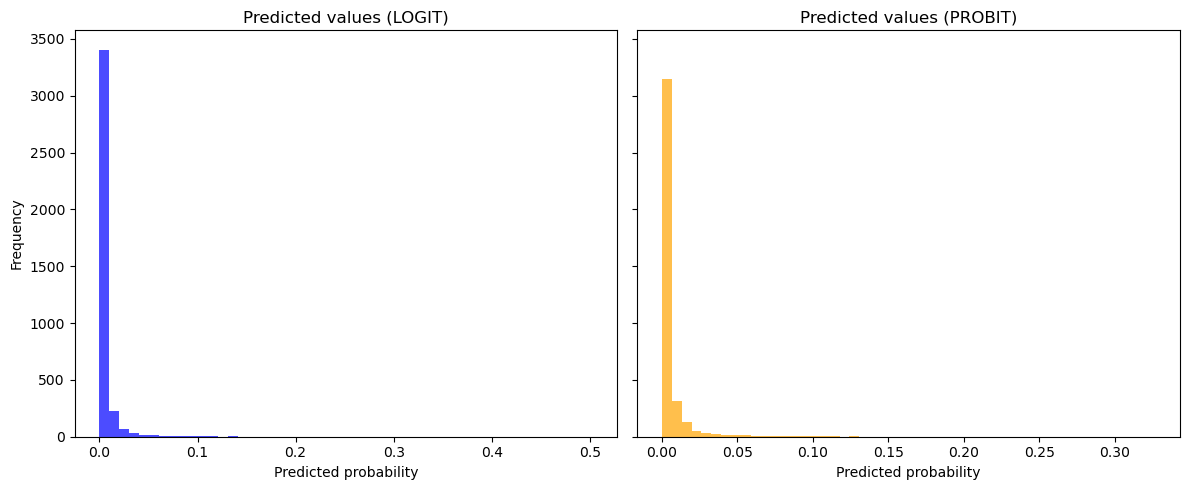

In [468]:
## Distribution of predicted values for logit and probit model 3 (preffered?)
logit_model_3 = logit_models_theta[2]
probit_model_3 = probit_models_theta[2]
x = df[x3].values
pred_logit = logit.G(x@logit_model_3)
pred_probit = probit.G(x@probit_model_3)

fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

ax[0].hist(pred_logit, bins=50, alpha=0.7, color='blue')
ax[0].set_title('Predicted values (LOGIT)')
ax[0].set_xlabel('Predicted probability')
ax[0].set_ylabel('Frequency')

ax[1].hist(pred_probit, bins=50, alpha=0.7, color='orange')
ax[1].set_title('Predicted values (PROBIT)')
ax[1].set_xlabel('Predicted probability')

plt.tight_layout()

print('---- LOGIT ----')
print(f'Mean: {pred_logit.mean()}')
print(f'Pred max: {pred_logit.max()}')
print(f'# above 50 percent: {len(pred_logit[pred_logit>0.5])}')

print('---- PROBIT ----')
print(f'Mean: {pred_probit.mean()}')
print(f'Pred max: {pred_probit.max()}')
print(f'# above 50 percent: {len(pred_probit[pred_probit>0.5])}')

In [469]:
### Parameter estimates for table 1

In [470]:
# Printing out all model results. For probit and logit, std. errors are robust to misspecification
print('LPM')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(LPM_models[i])

print('-----------------------')
print('-----------------------')
print('PROBIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(probit_models[i])

print('-----------------------')
print('-----------------------')
print('LOGIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(logit_models[i])

LPM
----Model 0----
         b_hat      se       t
const   0.0032  0.0011  3.0048
sblack  0.0039  0.0042  0.9275
shisp   0.0123  0.0064  1.9322
sother  0.0022  0.0055  0.4004
----Model 1----
                b_hat      se       t
const          0.0135  0.0098  1.3759
sblack         0.0019  0.0043  0.4450
shisp          0.0090  0.0060  1.5083
sother         0.0001  0.0057  0.0208
sage           0.0001  0.0003  0.2041
sage_sq       -0.0000  0.0000 -0.7378
smale          0.0048  0.0023  2.1054
sempl         -0.0065  0.0036 -1.7997
sincome_1     -0.0015  0.0033 -0.4416
sincome_3     -0.0002  0.0028 -0.0557
spop_1        -0.0080  0.0050 -1.6119
spop_3        -0.0045  0.0082 -0.5516
spop_4         0.0038  0.0105  0.3637
inctype_lin_1  0.0313  0.0150  2.0847
----Model 2----
                b_hat      se       t
const          0.0146  0.0103  1.4253
sblack         0.0024  0.0045  0.5365
shisp          0.0092  0.0060  1.5477
sother         0.0001  0.0057  0.0260
sage           0.0001  0.0003  0.

In [471]:
## Likelihood for probit and logit
print('PROBIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(criterion_probit[i])

print('-----------------------')
print('-----------------------')
print('LOGIT')
for i,model in enumerate(models):
    print(f'----Model {i}----')
    print(criterion_logit[i])

PROBIT
----Model 0----
-115.64202981855904
----Model 1----
-96.53481803715466
----Model 2----
-95.30996330792183
----Model 3----
-83.05802189296055
-----------------------
-----------------------
LOGIT
----Model 0----
-115.64206417553696
----Model 1----
-97.12336518906756
----Model 2----
-96.07414853952868
----Model 3----
-84.10628102951016


## OBS OBS OBS: LR-TEST ASSUMES CORRECT SPECIFICATION OF UNRESTRICTED MODEL! WE SHOULD USE A ROBUST WALD TEST INSTEAD

In [ ]:
## Likelihood ratio tests for nested models for probit and logit
alpha = 0.05

LR_test_probit = {}
LR_test_logit = {}

for i in range(len(models) - 1):
    freedom = len(models[i + 1]) - len(models[i])
    critical_value = chi2.ppf(1 - alpha, freedom)
    key = f'model{i}_to_{i + 1}'

    for results, criterion in [
        (LR_test_probit, criterion_probit),
        (LR_test_logit, criterion_logit),
    ]:
        LR = -2 * (criterion[i] - criterion[i + 1])
        pval = chi2.sf(LR, freedom)

        results[key] = {
            'LR_statistic': LR,
            'Degree_freedom': freedom,
            'critical_value': critical_value,
            'degrees_of_freedom': freedom,
            'p_value': pval,
        }

        print(f'{key}: LR={LR:.4f}, critical value={critical_value:.4f}, p-value={pval:.4g}')
    print()



#### ROBUST WALD TEST



model0_to_1: LR=38.2144, critical value=18.3070, p-value=3.482e-05
model0_to_1: LR=37.0374, critical value=18.3070, p-value=5.576e-05

model1_to_2: LR=2.4497, critical value=5.9915, p-value=0.2938
model1_to_2: LR=2.0984, critical value=5.9915, p-value=0.3502

model2_to_3: LR=24.5039, critical value=3.8415, p-value=7.416e-07
model2_to_3: LR=23.9357, critical value=3.8415, p-value=9.961e-07



## VOGUE TEST

In [473]:
# Estimated variance
N = y.shape[0]
x = df[x2].values #If preffered model changes, this should change as well
probit_likelihood = probit.loglikelihood(probit_models_theta[1], y=y, x=x) # If preffered model changes, this should change as well
logit_likelihood = logit.loglikelihood(logit_models_theta[1], y=y, x=x) # If preffered model changes, this should change as well
diff = (probit_likelihood-logit_likelihood).reshape(-1,1)
eta_sq = 1/N * (diff.T @ diff).item()

# Test-statistic
denom = (eta_sq**(1/2)) / (N**(1/2))
num = diff.mean()
VMS = num / denom

# Critical value and p-value
z_critical = norm.ppf(0.975)
p_val = 2 * (1-norm.cdf(abs(VMS)))

print('VMS test (probit v.s logit) of model 2 yields:')
print(f'VMS = {VMS:.3f}, Critical value = {z_critical:.2f}, P value = {p_val:.3}')
print(f'Both models are misspecified = {p_val>0.05}')
print(f'Total log-likelihood value of probit = {probit_likelihood.sum():.3f}, Total log-like of logit = {logit_likelihood.sum():.3f}')



VMS test (probit v.s logit) of model 2 yields:
VMS = 0.654, Critical value = 1.96, P value = 0.513
Both models are misspecified = True
Total log-likelihood value of probit = -96.535, Total log-like of logit = -97.123


# Partiel effects at the avarage (PEA)

In [474]:
models = {"x1": x1, "x2": x2, "x3": x3, "x4": x4}
average_values = {}

for name, columns in models.items():
    average_values[name] = df[columns].to_numpy().mean(axis=0)

print(average_values["x1"])  # averages in the same order as the columns in x1
print(average_values["x2"]) 

counterfactual = {"sblack": 0, "shisp": 0, "sother": 0} #White

for name, columns in models.items():
    for variable, value in counterfactual.items():
        average_values[name][columns.index(variable)] = value

print(average_values["x1"])  # updated averages in the same order as the columns in x1
print(average_values["x2"]) 

[1.         0.11055541 0.10160569 0.04869703]
[1.00000000e+00 1.10555409e-01 1.01605686e-01 4.86970255e-02
 4.10100026e+01 1.94247460e+03 5.29613056e-01 6.95446170e-01
 2.90866017e-01 4.55646223e-01 7.68886549e-01 4.00105291e-02
 4.58015267e-02 4.15898921e-02]
[1. 0. 0. 0.]
[1.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 4.10100026e+01 1.94247460e+03 5.29613056e-01 6.95446170e-01
 2.90866017e-01 4.55646223e-01 7.68886549e-01 4.00105291e-02
 4.58015267e-02 4.15898921e-02]


In [475]:
#manual try effect 
values_white = average_values["x2"].copy()
values_black = average_values["x2"].copy()

columns = x2 # Added by Mathias for readability. 
sblack_index = columns.index("sblack")
values_black[sblack_index] = 1

values_white = values_white.reshape(1, -1)
values_black = values_black.reshape(1, -1)


probit_effect_black = probit.predict(probit_models_theta[1], values_black)[0]
probit_effect_white = probit.predict(probit_models_theta[1], values_white)[0]
diff = probit_effect_black - probit_effect_white

print(f'Probit effect for black: {probit_effect_black}')
print(f'Probit effect for white: {probit_effect_white}')
print(f'Difference: {diff}')


Probit effect for black: 0.001452436005737984
Probit effect for white: 0.0011006588028233005
Difference: 0.0003517772029146835


In [476]:
#Manual try std
b_pr=probit_models_theta[1]
K = len(b_pr)
gx0 = norm.pdf(values_white@b_pr)
gx2 = norm.pdf(values_black@b_pr)

#grad_c_pr = gx0*(np.eye(K) - bb @ xx)
grad_d_pr = gx2*values_black - gx0*values_white




In [477]:
#print(grad_c_pr.shape == (K,K))
print(grad_d_pr.shape == (1,K))

True


In [478]:
def get_se(grad, cov):
    cov_me = grad@cov@grad.T
    return np.sqrt(np.diag(cov_me))

#se_c_pr = get_se(grad_c_pr, probit_cov[1])
se_d_pr = get_se(grad_d_pr, probit_cov[1])

In [479]:
print(f'PEA og Db: {diff}')
print(f'Standard errors: {se_d_pr}')

PEA og Db: 0.0003517772029146835
Standard errors: [0.00113749]


In [480]:
PEA_rows = []

for i, (name, columns) in enumerate(models.items()):
    values_white = average_values[name].copy()      # 1D array with avg. of x and all race dummies to 0 (=white)
    values_black = average_values[name].copy()

    sblack_index = columns.index("sblack")
    values_black[sblack_index] = 1              #  Set sblack = 1 for blacks.

    # predict() expects a 2D array, even for one observation
    values_white = values_white.reshape(1, -1)
    values_black = values_black.reshape(1, -1)

    beta_pr = probit_models_theta[i]#.to_numpy()      # Get coef. estimates for relevant model
    z_white_pr = (values_white @ beta_pr)[0]
    z_black_pr = (values_black @ beta_pr)[0]
    probit_effect = (
        probit.predict(beta_pr, values_black)[0]
        - probit.predict(beta_pr, values_white)[0]
    )
    grad_probit = (
        norm.pdf(z_black_pr) * values_black
        - norm.pdf(z_white_pr) * values_white
    )
    probit_se = get_se(grad_probit, probit_cov[i])[0]       # Get std. errors (C@Avar(\theta)@C')

    beta_lg = logit_models[i]["theta"].to_numpy()
    z_white_lg = (values_white @ beta_lg)[0]
    z_black_lg = (values_black @ beta_lg)[0]
    p_white_lg = logit.G(z_white_lg)
    p_black_lg = logit.G(z_black_lg)
    logit_effect = (
        logit.predict(logit_models[i]["theta"], values_black)[0]
        - logit.predict(logit_models[i]["theta"], values_white)[0]
    )
    grad_logit = (                                      # G'(z) = G(z)[1-G(z)]
        p_black_lg * (1 - p_black_lg) * values_black
        - p_white_lg * (1 - p_white_lg) * values_white
    )
    logit_se = get_se(grad_logit, logit_cov[i])[0]

    PEA_rows.append({
        "Model": name,
        "Probit effect": probit_effect,
        "Probit s.e.": probit_se,
        "Logit effect": logit_effect,
        "Logit s.e.": logit_se,
    })

effects_table = pd.DataFrame(PEA_rows).set_index("Model")
effects_table

# For later: A tabel comparing hispanics to whites and a table comparing blacks to hispanics

,Probit effect,Probit s.e.,Logit effect,Logit s.e.
Model,,,,
x1,0.003933,0.004246,0.003934,0.004245
x2,0.000352,0.001137,0.000666,0.001214
x3,0.000515,0.001143,0.000765,0.001169
x4,0.000345,0.000737,0.000247,0.000796


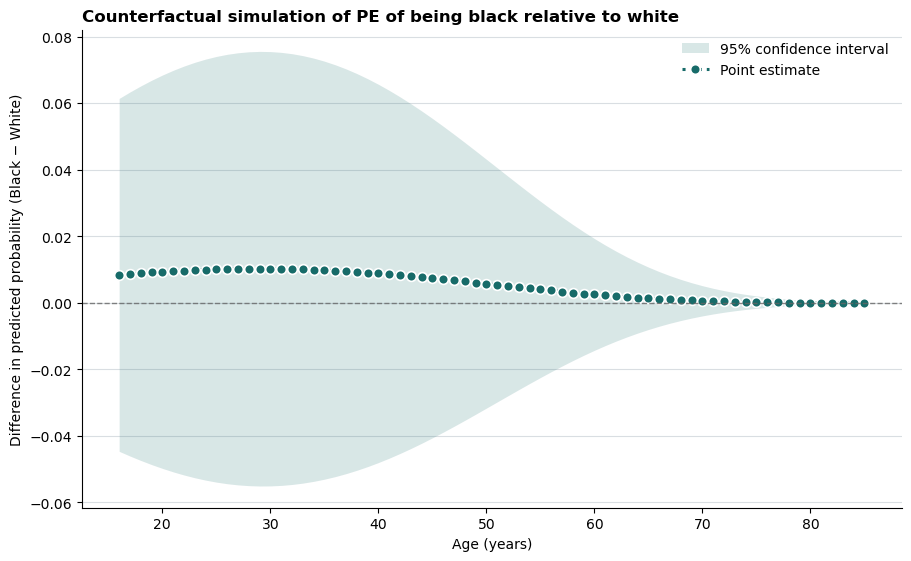

In [481]:
# Counterfactual analysis of a sample man: Male, employed, low-income, from big city, inctype_lin_1 = 1. 
age = 16
result_counterfactual = []
std_counterfactual = []
age_counterfactual = []
for i in range(70):
    sample_man = {
    'const': 1, 'sblack': 1, 'shisp': 0, 'sother': 0, 'sage': age,
    'sage_sq': age**2, 'smale': 1, 'sempl': 1, 'sincome_1': 1,
    'sincome_3': 0, 'spop_1': 0, 'spop_3': 0, 'spop_4': 1,
    'inctype_lin_1': 1
}
    sample_man_pd = pd.DataFrame(sample_man, index=[0])
    sample_man_np = sample_man_pd.to_numpy()
    sample_man_np_white = sample_man_np.copy()
    sample_man_np_white[:, 1] = 0
    
    beta_pr = probit_models_theta[1]#.to_numpy()

    z_white_pr = (sample_man_np_white @ beta_pr)[0]
    z_black_pr = (sample_man_np @ beta_pr)[0]
    probit_effect = (
        probit.predict(beta_pr, sample_man_np)[0]
        - probit.predict(beta_pr, sample_man_np_white)[0]
        )
    grad_probit = (
            norm.pdf(z_black_pr) * sample_man_np
            - norm.pdf(z_white_pr) * sample_man_np_white
        )
    probit_se = get_se(grad_probit, probit_cov[1])[0]


    result_counterfactual.append(probit_effect)
    std_counterfactual.append(probit_se)
    age_counterfactual.append(age)

    age = age + 1



# Figure
age_values = np.asarray(age_counterfactual)
estimate_values = np.asarray(result_counterfactual)
standard_errors = np.asarray(std_counterfactual)
ci_lower = estimate_values - 1.96 * standard_errors
ci_upper = estimate_values + 1.96 * standard_errors

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
ax.fill_between(
    age_values,
    ci_lower,
    ci_upper,
    color='#2B7A78',
    alpha=0.18,
    linewidth=0,
    label='95% confidence interval',
)
ax.plot(
    age_values,
    estimate_values,
    color='#176B69',
    linestyle=':',
    linewidth=2.2,
    marker='o',
    markersize=7,
    markerfacecolor='#176B69',
    markeredgecolor='white',
    markeredgewidth=1.2,
    label='Point estimate',
)
ax.axhline(0, color='#666666', linestyle='--', linewidth=1, alpha=0.8)
ax.set_xlabel('Age (years)')
ax.set_ylabel('Difference in predicted probability (Black − White)')
ax.set_title('Counterfactual simulation of PE of being black relative to white', loc='left', weight='bold')
age_tick_step = 10
first_age_tick = int(np.ceil(age_values.min() / age_tick_step) * age_tick_step)
ax.set_xticks(np.arange(first_age_tick, age_values.max() + 1, age_tick_step))
ax.grid(axis='y', color='#D9DEE2', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='best')
plt.show()


# Wald test for sig PEA

# Average Partial effects

### BLACK V.S WHITE and HISPANIC V.S WHITE

### Heterogenerity across income groups (APEs)

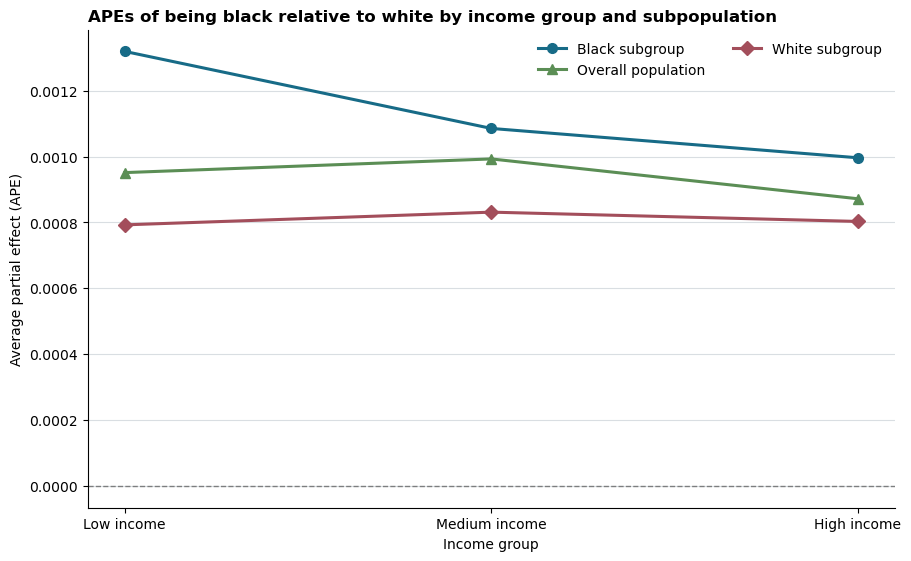

In [482]:
# Calculate partial effects for PREFFERED MODEL ONLY (I stick to x2 model)
pref = x2
pref_index = 1

def APE_inc(race, model_lab, model_index):
    white = df[model_lab].to_numpy()       # Convert df to numpy
    columns = model_lab                    # Extract labels
    counterfactual = {"sblack": 0, "shisp": 0, "sother": 0} #White
    for variable, value in counterfactual.items():
        white[:,columns.index(variable)] = value        # Set all race dummies to zero to make a white counterfactual.

    # blacks
    s_race = white.copy()
    s_race[:, columns.index(race)] = 1 

    PE_probit_vec = (
        probit.predict(probit_models_theta[model_index], s_race) - probit.predict(probit_models_theta[model_index], white))


    return PE_probit_vec       




#### Select relevant subgroups
# Blacks with low income
b_li = df[(df['sblack'] == 1) & (df['sincome_1'] == 1)].index
# Black with medium income
b_mi = df[(df['sblack']==1) & (df['sincome_1'] == 0) & (df['sincome_3'] == 0)].index
# Black with high income
b_hi = df[(df['sblack']==1) & (df['sincome_3'] == 1)].index

# Hisp with low income
h_li = df[(df['shisp'] == 1) & (df['sincome_1'] == 1)].index
# Hisp with medium income
h_mi = df[(df['shisp']==1) & (df['sincome_1'] == 0) & (df['sincome_3'] == 0)].index
# Hisp with high income
h_hi = df[(df['shisp']==1) & (df['sincome_3'] == 1)].index

# white with low income
w_li = df[(df['sblack'] == 0) & (df['shisp'] == 0) & (df['sother'] == 0) & (df['sincome_1'] == 1)].index
# white with medium income
w_mi = df[(df['sblack'] == 0) & (df['shisp'] == 0) & (df['sother'] == 0) & (df['sincome_1'] == 0) & (df['sincome_3'] == 0)].index
# white with high income
w_hi = df[(df['sblack'] == 0) & (df['shisp'] == 0) & (df['sother'] == 0) & (df['sincome_3'] == 1)].index



# Overall, income
li = df[(df['sincome_1'] == 1)].index
mi = df[(df['sincome_1'] == 0) & (df['sincome_3'] == 0)].index
hi = df[(df['sincome_3'] == 1)].index


# APEs
# Black v.s. white (black sub)
APE_blacks = []
for val in [b_li, b_mi, b_hi]:
    prob = APE_inc(race='sblack', model_lab=x2, model_index=1)
    APE_blacks.append(
        prob[val].mean().item()
    )

# Black v.s white (overall)
APE_overall_black = []
for val in [li, mi, hi]:
    prob = APE_inc(race='sblack', model_lab=x2, model_index=1)
    APE_overall_black.append(
        prob[val].mean().item()
    )

# Black v.s white (white sub)
APE_BW_white_sub= []
for val in [w_li, w_mi, w_hi]:
    prob = APE_inc(race='sblack', model_lab=x2, model_index=1)
    APE_BW_white_sub.append(
        prob[val].mean().item()
    )



### Figure
income_groups = ['Low income', 'Medium income', 'High income']
ape_series = {
    'Black subgroup': APE_blacks,
    'Overall population': APE_overall_black,
    'White subgroup': APE_BW_white_sub,
}

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
colors = ['#176B87', '#5B8E55', '#A34E5B']
markers = ['o', '^', 'D']

for (label, values), color, marker in zip(ape_series.items(), colors, markers):
    ax.plot(
        income_groups,
        values,
        label=label,
        color=color,
        marker=marker,
        linewidth=2.2,
        markersize=7,
    )

ax.axhline(0, color='#555555', linewidth=1, linestyle='--', alpha=0.7)
ax.set_xlabel('Income group')
ax.set_ylabel('Average partial effect (APE)')
ax.set_title('APEs of being black relative to white by income group and subpopulation', loc='left', weight='bold')
ax.grid(axis='y', color='#D9DEE2', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='best')
plt.show()


In [483]:
# Tabulation to see how many have experienced force within each subgroup.
black = dat[dat['sblack']==1]
hispanic = dat[dat['shisp']==1]
white = dat[dat['swhite']==1]
other = dat[dat['sother']==1]
print(pd.crosstab(black['sincome'], black['anyuseofforce_coded']))
print(pd.crosstab(hispanic['sincome'], hispanic['anyuseofforce_coded']))
print(pd.crosstab(white['sincome'], white['anyuseofforce_coded']))
print(pd.crosstab(other['sincome'], other['anyuseofforce_coded']))

anyuseofforce_coded    0  1
sincome                    
1                    153  1
2                    138  1
3                    126  1
anyuseofforce_coded    0  1
sincome                    
1                    129  2
2                    122  3
3                    129  1
anyuseofforce_coded     0  1
sincome                     
1                     764  3
2                     659  2
3                    1376  4
anyuseofforce_coded   0  1
sincome                   
1                    53  0
2                    38  0
3                    93  1


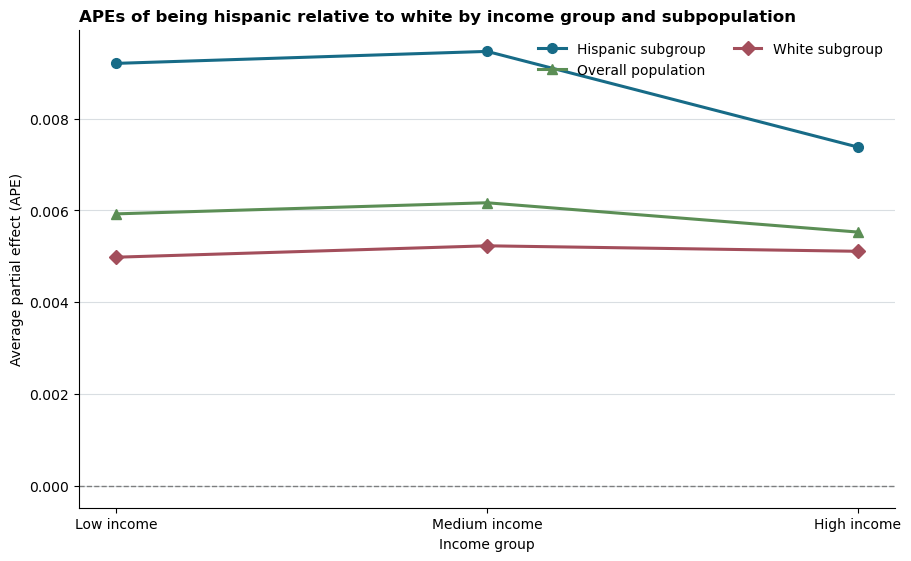

In [484]:
## Hispanic v.s white

# Hisp v.s. white (hisp sub)
APE_hisp = []
for val in [h_li, h_mi, h_hi]:
    prob = APE_inc(race='shisp', model_lab=x2, model_index=1)
    APE_hisp.append(
        prob[val].mean().item()
    )
# Hisp v.s. white (white sub)
APE_hisp_white = []
for val in [w_li, w_mi, w_hi]:
    prob = APE_inc(race='shisp', model_lab=x2, model_index=1)
    APE_hisp_white.append(
        prob[val].mean().item()
    )
# Hisp v.s. white (full)
APE_hisp_white_overall = []
for val in [li, mi, hi]:
    prob = APE_inc(race='shisp', model_lab=x2, model_index=1)
    APE_hisp_white_overall.append(
        prob[val].mean().item()
    )

### Figure
income_groups = ['Low income', 'Medium income', 'High income']
ape_series = {
    'Hispanic subgroup': APE_hisp,
    'Overall population': APE_hisp_white_overall,
    'White subgroup': APE_hisp_white,
}

fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
colors = ['#176B87', '#5B8E55', '#A34E5B']
markers = ['o', '^', 'D']

for (label, values), color, marker in zip(ape_series.items(), colors, markers):
    ax.plot(
        income_groups,
        values,
        label=label,
        color=color,
        marker=marker,
        linewidth=2.2,
        markersize=7,
    )

ax.axhline(0, color='#555555', linewidth=1, linestyle='--', alpha=0.7)
ax.set_xlabel('Income group')
ax.set_ylabel('Average partial effect (APE)')
ax.set_title('APEs of being hispanic relative to white by income group and subpopulation', loc='left', weight='bold')
ax.grid(axis='y', color='#D9DEE2', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=2, loc='best')
plt.show()